In [47]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [48]:
df = pd.read_csv("/Users/jasleenkaur/markovate-assessment/data/raw/bank.csv")

In [49]:
X = df.drop(columns=["deposit", "duration"])
Y = df["deposit"].map({"no": 0, "yes": 1})

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [50]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

In [51]:
logistic_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

random_forest_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

In [52]:
logistic_model = Pipeline([
    ("preprocessing", logistic_preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

In [53]:
random_forest_model = Pipeline([
    ("preprocessing", random_forest_preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

In [54]:
logistic_model.fit(X_train, Y_train)
random_forest_model.fit(X_train, Y_train)
print("Both Models Trained Successfully")

Both Models Trained Successfully


In [55]:
y_logistic_pred = logistic_model.predict(X_test)
y_rf_pred = random_forest_model.predict(X_test)
print("Predictions Generated Successfully")

Predictions Generated Successfully


In [56]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [57]:
print("Logistic Regression:")
print("Accuracy:", accuracy_score(Y_test, y_logistic_pred))
print("Precision:", precision_score(Y_test, y_logistic_pred))
print("Recall:", recall_score(Y_test, y_logistic_pred))
print("F1 Score:", f1_score(Y_test, y_logistic_pred))

Logistic Regression:
Accuracy: 0.6954769368562472
Precision: 0.7327586206896551
Recall: 0.5623818525519849
F1 Score: 0.6363636363636364


In [58]:
print("Random Forest")
print("Accuracy:", accuracy_score(Y_test, y_rf_pred))
print("Precision:", precision_score(Y_test, y_rf_pred))
print("Recall:", recall_score(Y_test, y_rf_pred))
print("F1 Score:", f1_score(Y_test, y_rf_pred))

Random Forest
Accuracy: 0.7232422749664129
Precision: 0.7477477477477478
Recall: 0.6275992438563327
F1 Score: 0.6824254881808839


In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

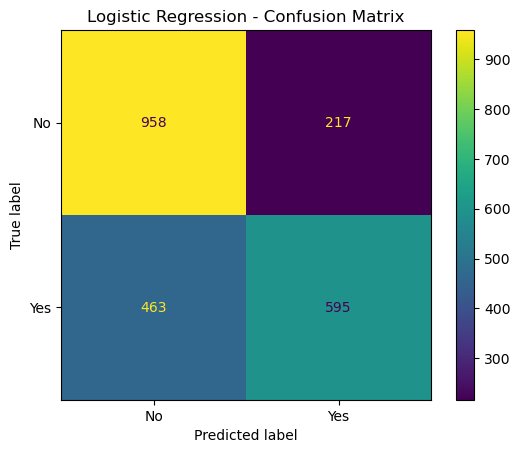

In [60]:
cm_logistic = confusion_matrix(Y_test, y_logistic_pred)
ConfusionMatrixDisplay(
    confusion_matrix = cm_logistic,
    display_labels = ["No", "Yes"]
).plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

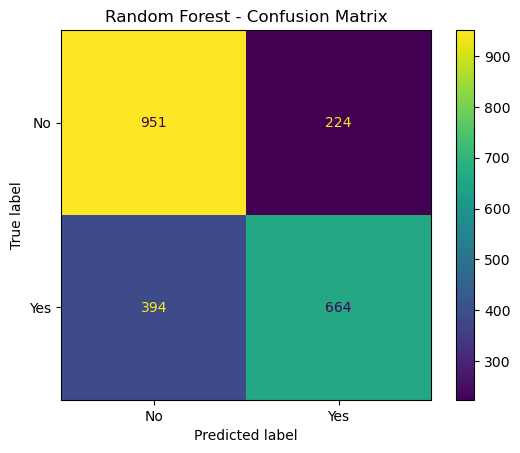

In [61]:
cm_rf = confusion_matrix(Y_test, y_rf_pred)
ConfusionMatrixDisplay(
    confusion_matrix = cm_rf,
    display_labels = ["No", "Yes"]
).plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [62]:
from sklearn.metrics import roc_auc_score

In [63]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

auc_logistic = roc_auc_score(Y_test, y_prob_logistic)
auc_rf = roc_auc_score(Y_test, y_prob_rf)

print("Logistic Regression ROC-AUC:", round(auc_logistic, 4))
print("Random Forest ROC-AUC:", round(auc_logistic, 4))

Logistic Regression ROC-AUC: 0.7579
Random Forest ROC-AUC: 0.7579


In [64]:
from sklearn.metrics import roc_curve

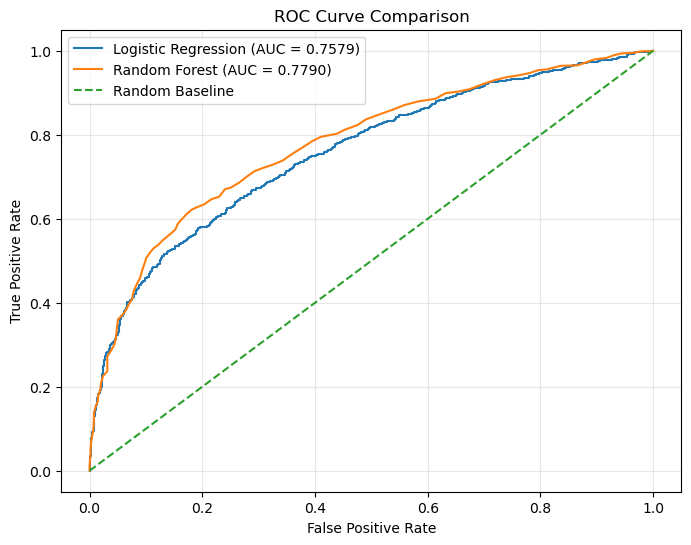

In [65]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    Y_test, y_prob_logistic
)

fpr_rf, tpr_rf, _ = roc_curve(
    Y_test, y_prob_rf
)

plt.figure(figsize=(8,6))
plt.plot(
    fpr_logistic, tpr_logistic,
    label = f"Logistic Regression (AUC = {auc_logistic:.4f})"
)
plt.plot(
    fpr_rf, tpr_rf, 
    label = f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle = "--", label = "Random Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [66]:
rf_classifier = random_forest_model.named_steps["model"]
feature_names = (
    random_forest_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
print(importance_df.head(15))

                     Feature  Importance
1               num__balance    0.151389
0                   num__age    0.131255
2                   num__day    0.117028
3              num__campaign    0.065316
4                 num__pdays    0.042890
48     cat__poutcome_success    0.032173
33      cat__contact_unknown    0.026102
5              num__previous    0.022929
31     cat__contact_cellular    0.018544
27           cat__housing_no    0.017524
22  cat__education_secondary    0.016549
28          cat__housing_yes    0.015622
23   cat__education_tertiary    0.014921
34            cat__month_apr    0.014643
15       cat__job_technician    0.014624


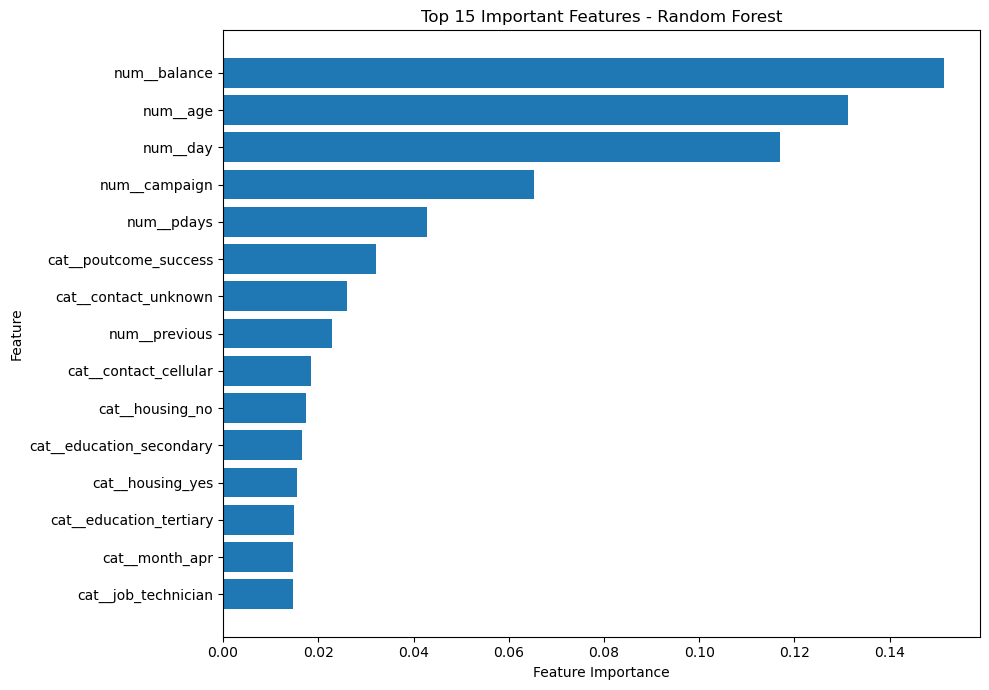

In [67]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)
plt.figure(figsize=(10,7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features - Random Forest")
plt.tight_layout()
plt.show()

In [68]:
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        0.6955,
        0.7328,
        0.5624,
        0.6364,
        auc_logistic
    ],
    "Random Forest": [
        0.7232,
        0.7477,
        0.6276,
        0.6824,
        auc_rf
    ]
})

comparison_df = comparison_df.round(4)
comparison_df

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.6955,0.7232
1,Precision,0.7328,0.7477
2,Recall,0.5624,0.6276
3,F1-Score,0.6364,0.6824
4,ROC-AUC,0.7579,0.7790


In [69]:
import joblib
import os

In [70]:
os.makedirs("../models", exist_ok=True)
joblib.dump(
    random_forest_model,
    "../models/random_forest_model.pkl"
)
print("Random Forest model saved successfully")

Random Forest model saved successfully


In [71]:
model_path = "../models/random_forest_model.pkl"
if os.path.exists(model_path):
    print("Model file exists!")
    print(f"File Size: {os.path.getsize(model_path)/1024:.2f} KB")
    loaded_model = joblib.load(model_path)
    print("Model loaded successfully!")
else:
    print("Model file not found. Check the file path")

Model file exists!
File Size: 38803.02 KB
Model loaded successfully!


In [72]:
loaded_predictions = loaded_model.predict(X_test)
print(
    "Predictions Match:",
    (loaded_predictions == y_rf_pred).all()
)

Predictions Match: True
